# Лабораторная 3 Визуализация и разведочный анализ

**Иноземцев Сергей Викторович · ЕТ-216**

Все части работы собраны в одном ноутбуке. Выполнять сверху вниз в новом ядре. Таблицы находятся рядом; графики отображаются только внутри ноутбука. Источник заданий: [курс edu.susu.ru](https://edu.susu.ru/course/view.php?id=218588).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 25)
pd.set_option('display.max_rows', 25)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})
DATA = Path('lab3') if Path('lab3').is_dir() else Path('.')

def show(name=None):
    """Показать график в ноутбуке без создания внешних файлов."""
    plt.tight_layout()
    plt.show()
    plt.close('all')


## Визуализация Pandas Matplotlib Seaborn

### Проверка исходных данных StudentsPerformance
Реальный файл из вложения курса. В условии опечатка gender=mail; используется существующее значение male.

In [2]:
df = pd.read_csv(DATA / 'StudentsPerformance.csv')
scores = ['math score', 'reading score', 'writing score']
print(df.shape)
df.info()
display(df.head())
display(df.describe(include='all'))
display(df.isna().sum())
print('Полных совпадений строк:', df.duplicated().sum())
assert df[scores].ge(0).all().all() and df[scores].le(100).all().all()

(1000, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
count,1000,1000,1000,1000,1000,1000.00000,1000.000000,1000.000000
unique,2,5,6,2,2,NaN,NaN,NaN
top,female,group C,some college,standard,none,NaN,NaN,NaN
freq,518,319,226,645,642,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,66.08900,69.169000,68.054000
std,NaN,NaN,NaN,NaN,NaN,15.16308,14.600192,15.195657
min,NaN,NaN,NaN,NaN,NaN,0.00000,17.000000,10.000000
25%,NaN,NaN,NaN,NaN,NaN,57.00000,59.000000,57.750000
50%,NaN,NaN,NaN,NaN,NaN,66.00000,70.000000,69.000000
75%,NaN,NaN,NaN,NaN,NaN,77.00000,79.000000,79.000000


gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Полных совпадений строк: 0


### Pandas Три диаграммы

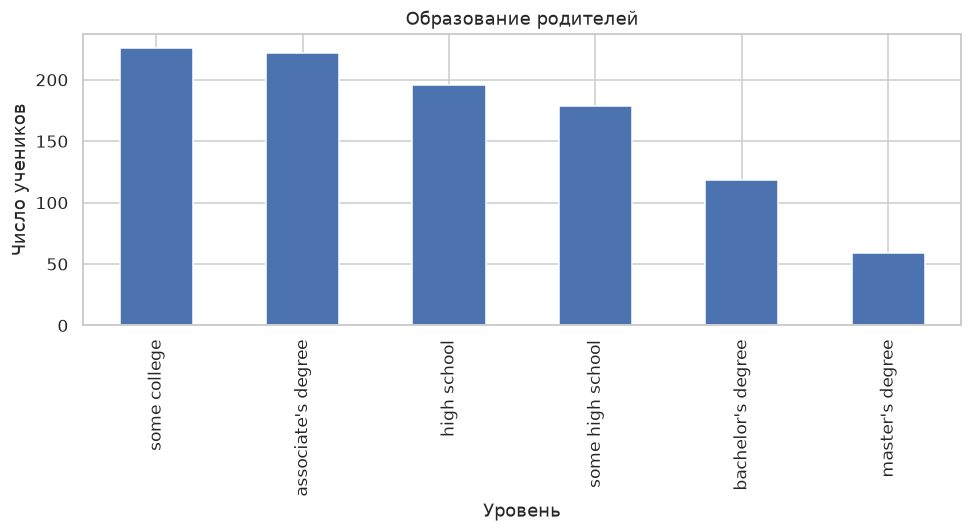

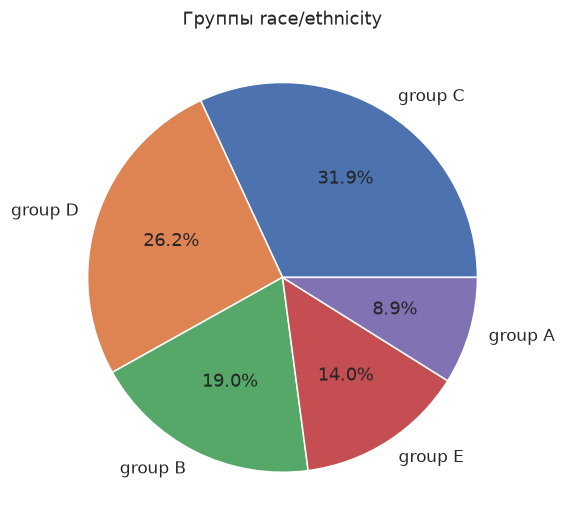

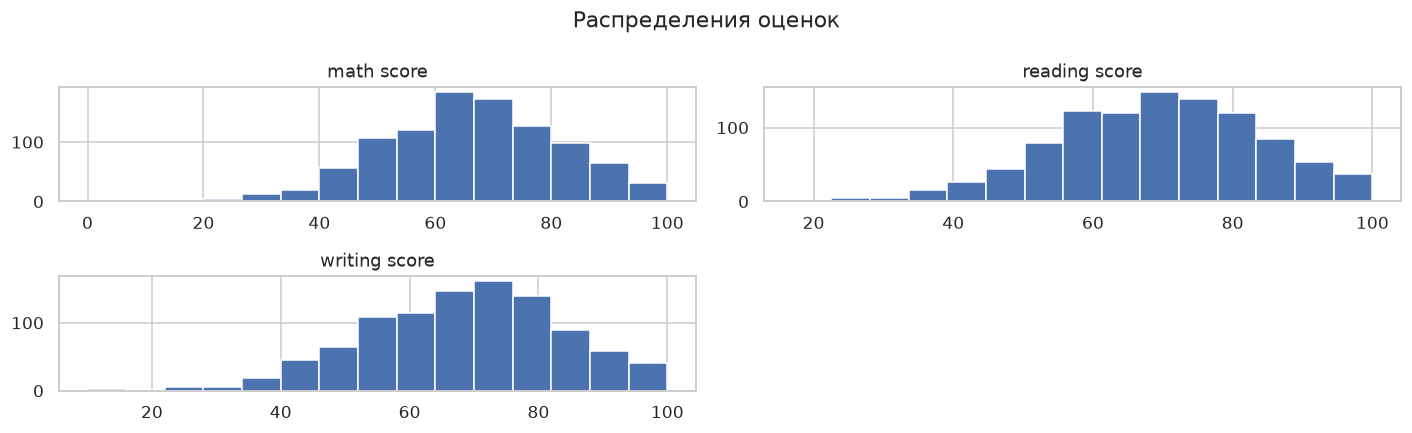

In [3]:
df['parental level of education'].value_counts().plot.bar()
plt.title('Образование родителей')
plt.xlabel('Уровень')
plt.ylabel('Число учеников')
show('parent_education')
df['race/ethnicity'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title('Группы race/ethnicity')
plt.ylabel('')
show('ethnicity')
df[scores].hist(bins=15, figsize=(13, 4))
plt.suptitle('Распределения оценок')
show('score_histograms')

### Matplotlib Сетка 3 на 2

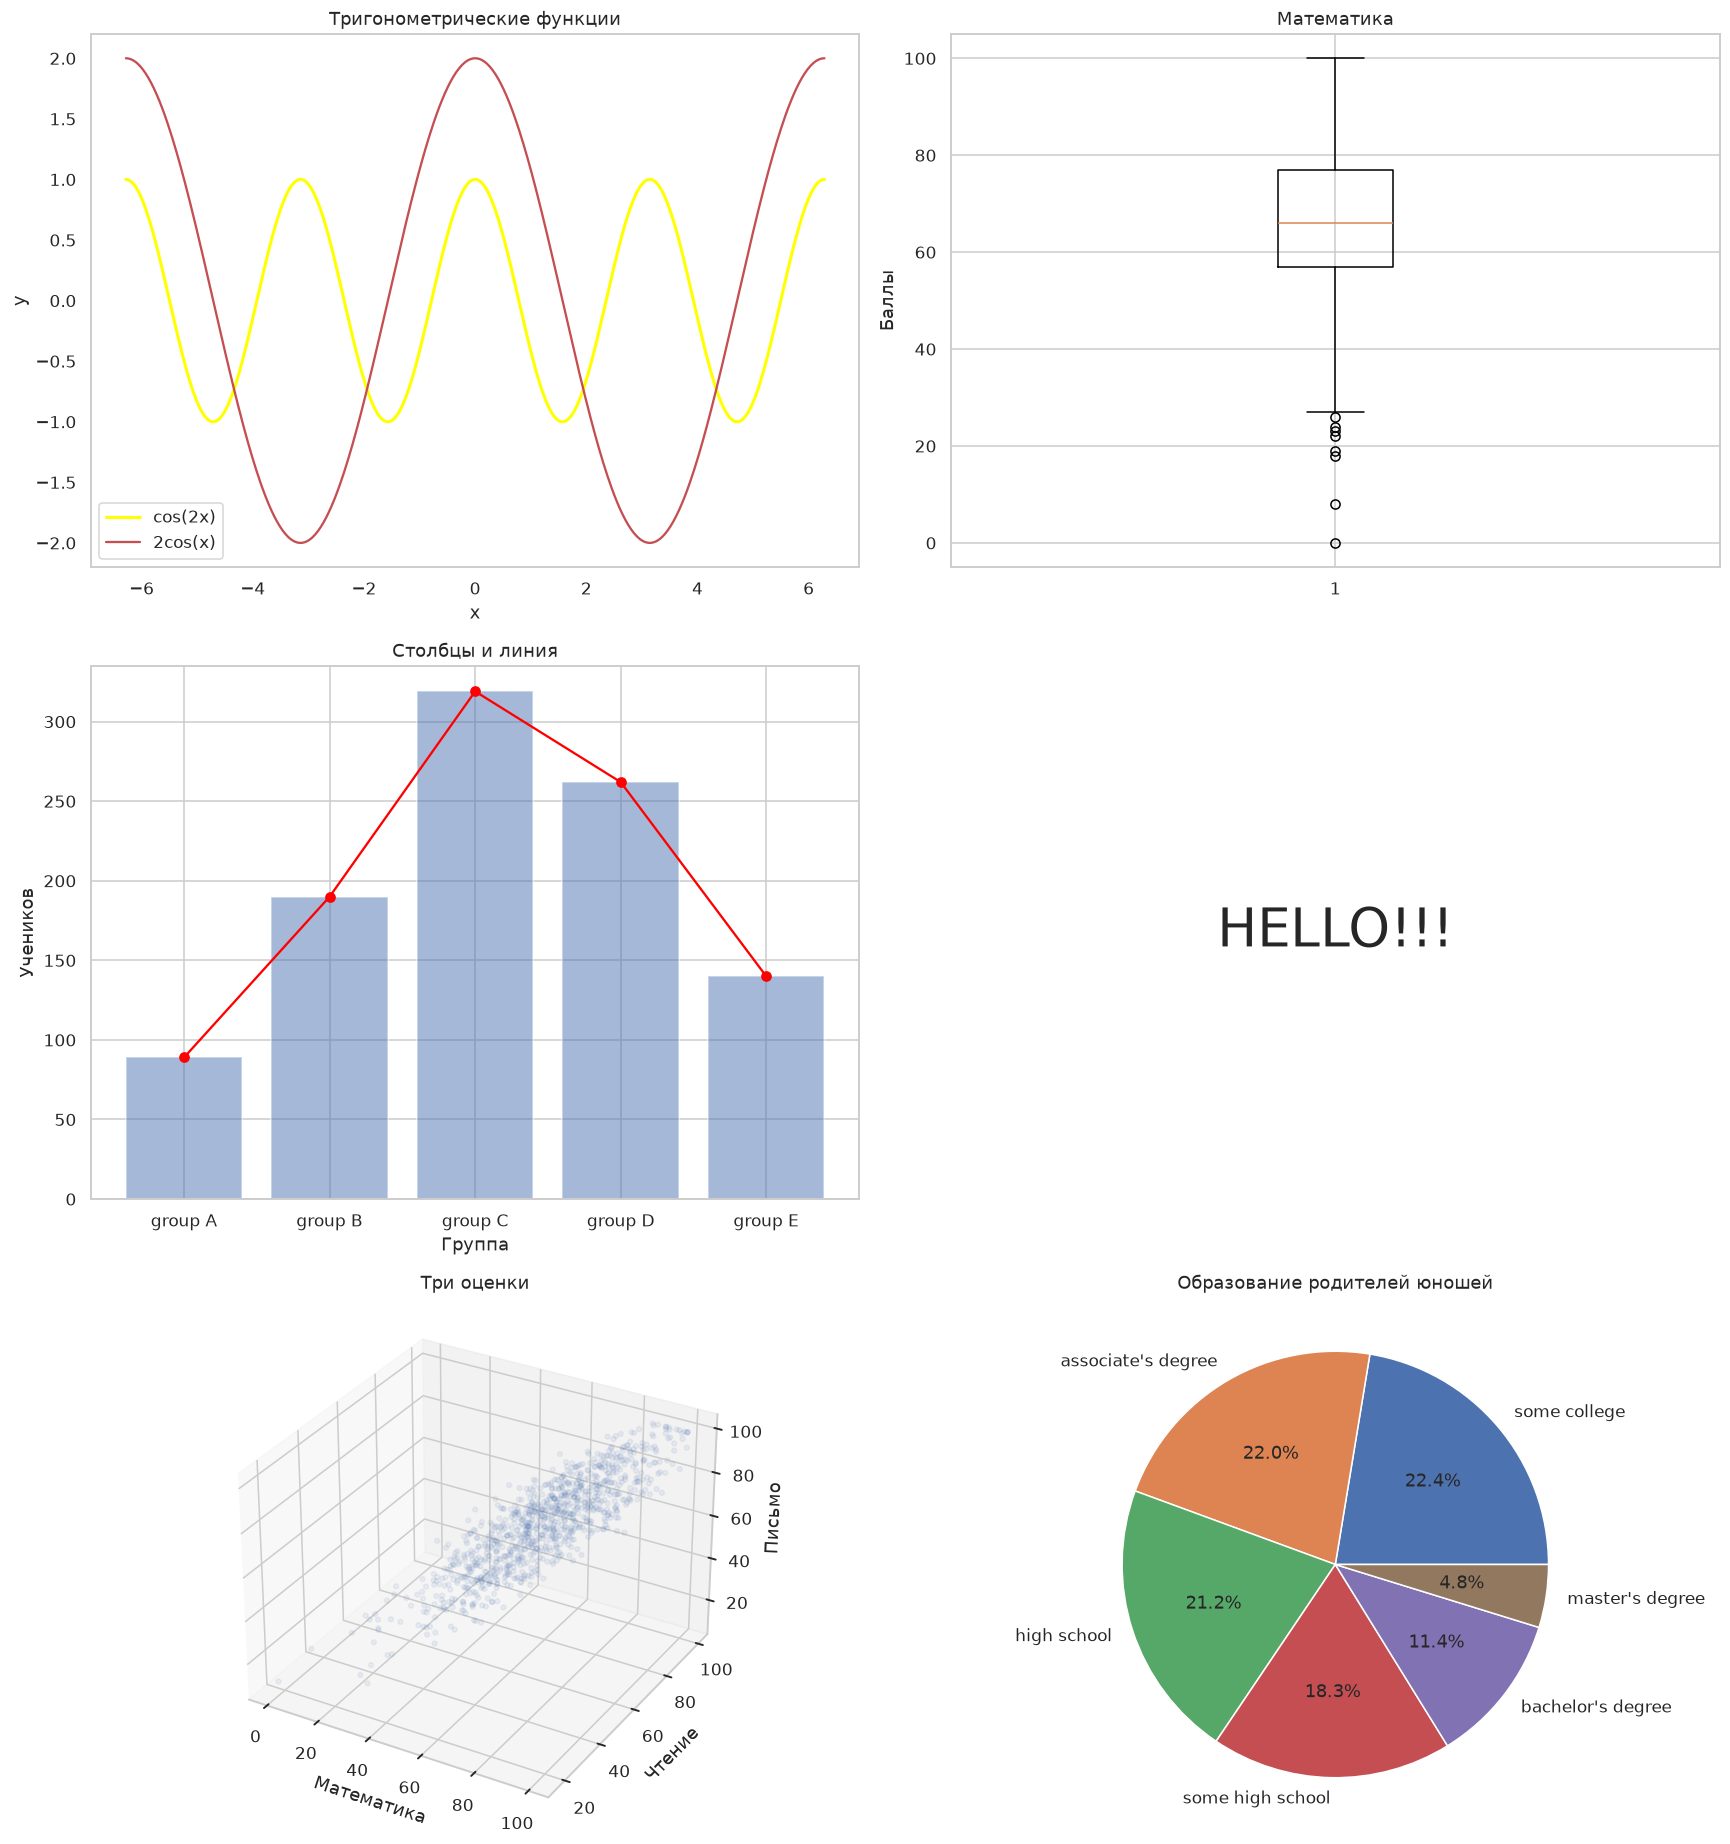

In [4]:
fig = plt.figure(figsize=(16, 17))
ax = fig.add_subplot(321)
x = np.linspace(-2 * np.pi, 2 * np.pi, 500)
ax.plot(x, np.cos(2 * x), color='yellow', linewidth=2, label='cos(2x)')
ax.plot(x, 2 * np.cos(x), 'r', label='2cos(x)')
ax.grid()
ax.legend()
ax.set(title='Тригонометрические функции', xlabel='x', ylabel='y')
ax = fig.add_subplot(322)
ax.boxplot(df['math score'])
ax.set(title='Математика', ylabel='Баллы')
ax = fig.add_subplot(323)
cnt = df['race/ethnicity'].value_counts().sort_index()
ax.bar(cnt.index, cnt.values, alpha=0.5)
ax.plot(cnt.index, cnt.values, 'o-', color='red')
ax.set(title='Столбцы и линия', xlabel='Группа', ylabel='Учеников')
ax = fig.add_subplot(324)
ax.text(0.5, 0.5, 'HELLO!!!', ha='center', va='center', fontsize=35)
ax.axis('off')
ax = fig.add_subplot(325, projection='3d')
ax.scatter(df[scores[0]], df[scores[1]], df[scores[2]], s=10, alpha=0.3)
ax.set(xlabel='Математика', ylabel='Чтение', zlabel='Письмо', title='Три оценки')
ax = fig.add_subplot(326)
df.loc[df.gender.eq('male'), 'parental level of education'].value_counts().plot.pie(ax=ax, autopct='%1.1f%%')
ax.set(title='Образование родителей юношей', ylabel='')
show('matplotlib_grid')

### Seaborn Парные графики и корреляции

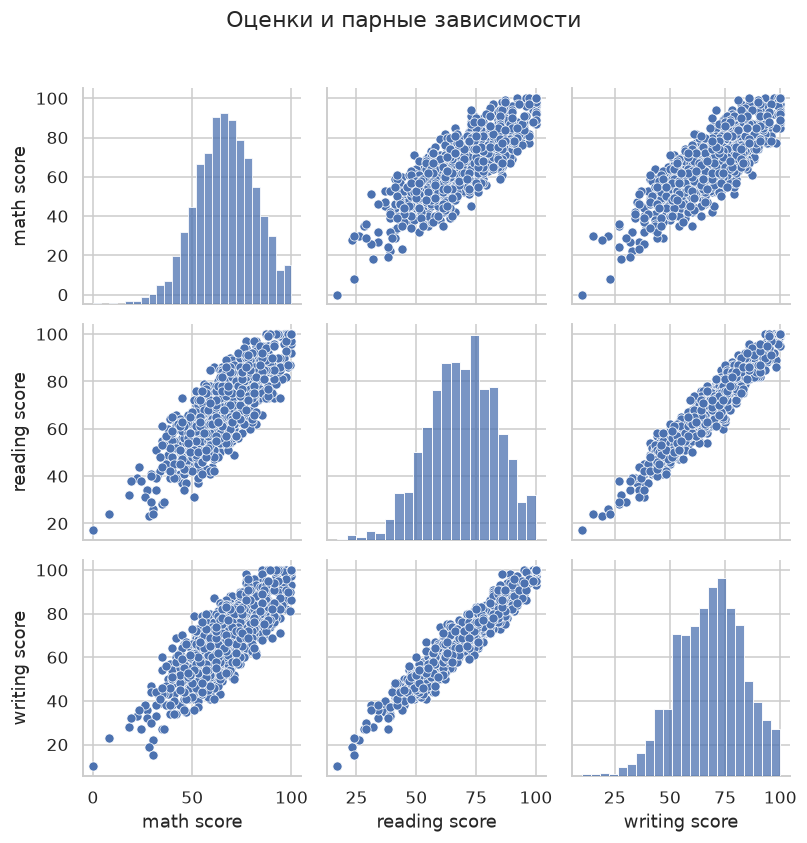

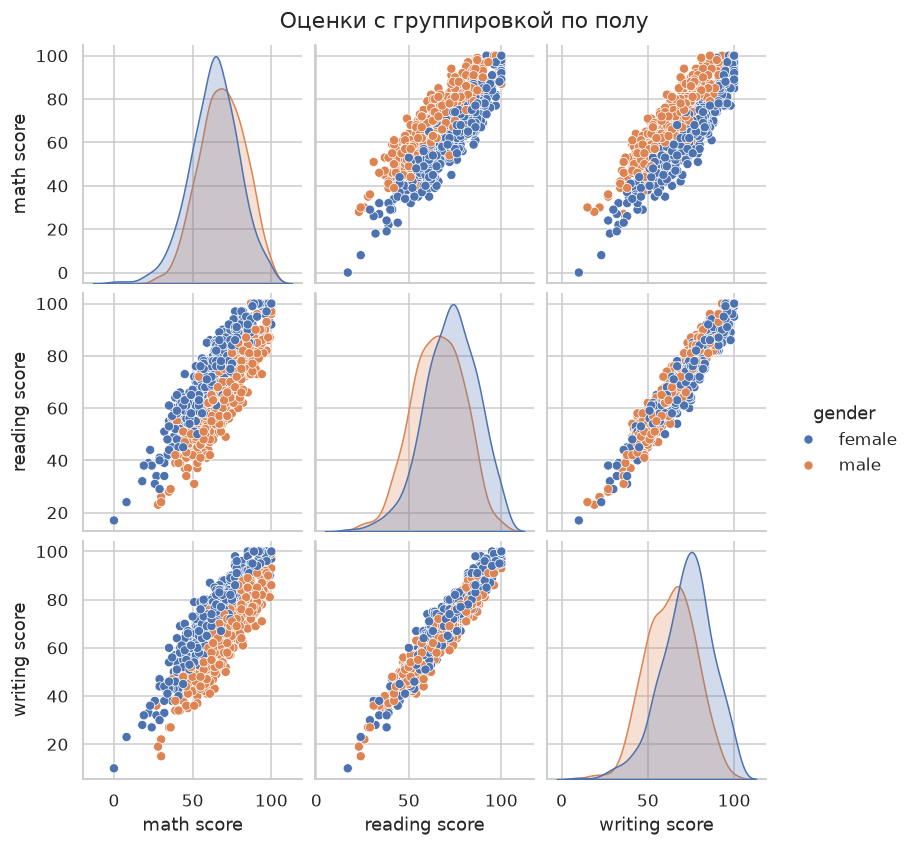

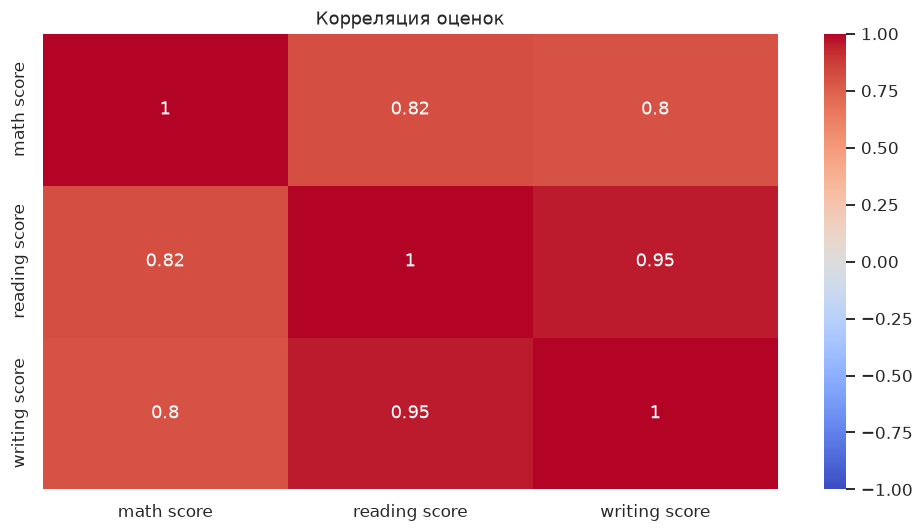

In [5]:
sns.pairplot(df[scores], diag_kind='hist')
plt.suptitle('Оценки и парные зависимости', y=1.02)
show('pair_hist')
grid = sns.pairplot(df[scores + ['gender']], hue='gender', diag_kind='kde')
grid.figure.suptitle('Оценки с группировкой по полу', y=1.02)
grid.figure.subplots_adjust(right=0.82)
sns.move_legend(grid, 'center left', bbox_to_anchor=(0.84, 0.5), borderaxespad=0)
plt.show()
plt.close('all')
sns.heatmap(df[scores].corr(), annot=True, vmin=-1, vmax=1, cmap='coolwarm')
plt.title('Корреляция оценок')
show('heatmap')

### Аномалии и вывод

In [6]:
q1, q3 = df['math score'].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = df[(df['math score'] < q1 - 1.5 * iqr) | (df['math score'] > q3 + 1.5 * iqr)]
print('Границы IQR:', q1 - 1.5 * iqr, q3 + 1.5 * iqr, 'Выбросов:', len(outliers))
display(outliers)
display(df.groupby('test preparation course')[scores].mean())
display(df.groupby('gender')[scores].mean())

Границы IQR: 27.0 107.0 Выбросов: 8


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
17,female,group B,some high school,free/reduced,none,18,32,28
59,female,group C,some high school,free/reduced,none,0,17,10
145,female,group C,some college,free/reduced,none,22,39,33
338,female,group B,some high school,free/reduced,none,24,38,27
466,female,group D,associate's degree,free/reduced,none,26,31,38
787,female,group B,some college,standard,none,19,38,32
842,female,group B,high school,free/reduced,completed,23,44,36
980,female,group B,high school,free/reduced,none,8,24,23


,math score,reading score,writing score
test preparation course,,,
completed,69.695531,73.893855,74.418994
none,64.077882,66.534268,64.504673


,math score,reading score,writing score
gender,,,
female,63.633205,72.608108,72.467181
male,68.728216,65.473029,63.311203


В файле 1000 учеников, 0 пропусков, 0 полных совпадений строк. Оценки укладываются в 0–100. По правилу 1,5 IQR выявлено 8 экстремальных оценок математики; это допустимые низкие баллы, а не автоматически ошибки. Самая сильная корреляция — между чтением и письмом: r=0.955. Наблюдаемые различия групп не доказывают причинного влияния пола, этнической группы или подготовки. Для этого нужны контроль смешивающих факторов и отдельный дизайн исследования.